# Diabetes Prediction 
## problem Statement 
### problem : predict whether the patient have diabetes or not
### important : catch all patient have diabetes (Recall)

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [42]:
df = pd.read_csv("../data/raw/diabetes_prediction_dataset.csv")
print(df.shape)
df.head()

(100000, 9)


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [43]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  str    
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  str    
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), str(2)
memory usage: 6.9 MB


In [44]:
print(df.isnull().sum())
print("Dublicated",df.duplicated().sum())

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64
Dublicated 3854


In [45]:
print(df["diabetes"].value_counts())
print(df["diabetes"].value_counts(normalize = True)*100)

diabetes
0    91500
1     8500
Name: count, dtype: int64
diabetes
0    91.5
1     8.5
Name: proportion, dtype: float64


In [46]:
df["smoking_history"].unique()

<StringArray>
['never', 'No Info', 'current', 'former', 'ever', 'not current']
Length: 6, dtype: str

Although it is state that the dataset contains no missing values it should be noted that the variable [smoking_history] includes the value "No Info.

In [47]:
df = df.drop_duplicates().reset_index(drop= True)
df.shape

(96146, 9)

In [48]:
df["diabetes"].value_counts(normalize = True) *100

diabetes
0    91.178
1     8.822
Name: proportion, dtype: float64

In [49]:
for col in ["gender","smoking_history"]:
    print(df[col].value_counts())

gender
Female    56161
Male      39967
Other        18
Name: count, dtype: int64
smoking_history
never          34398
No Info        32887
former          9299
current         9197
not current     6367
ever            3998
Name: count, dtype: int64


Gender also contains Other

In [50]:
(df["smoking_history"].value_counts(normalize=True)*100)

smoking_history
never          35.776839
No Info        34.205271
former          9.671749
current         9.565661
not current     6.622220
ever            4.158259
Name: proportion, dtype: float64

In [51]:
df[["age","bmi","blood_glucose_level","HbA1c_level"]].describe()

,age,bmi,blood_glucose_level,HbA1c_level
count,96146.000000,96146.000000,96146.000000,96146.000000
mean,41.794326,27.321461,138.218231,5.532609
std,22.462948,6.767716,40.909771,1.073232
min,0.080000,10.010000,80.000000,3.500000
25%,24.000000,23.400000,100.000000,4.800000
50%,43.000000,27.320000,140.000000,5.800000
75%,59.000000,29.860000,159.000000,6.200000
max,80.000000,95.690000,300.000000,9.000000


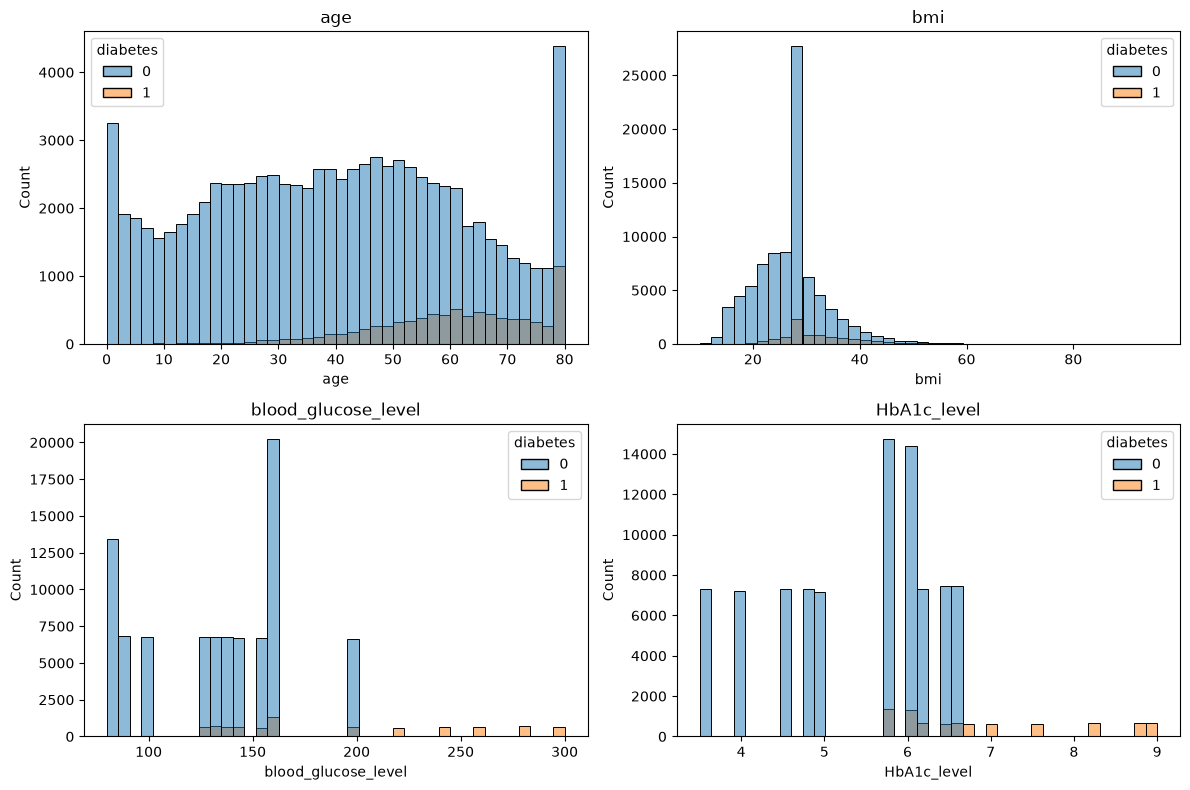

In [52]:
num_cols = ["age","bmi","blood_glucose_level","HbA1c_level"]
fig,axes = plt.subplots(2,2,figsize =(12,8))

for ax, col in zip(axes.ravel(),num_cols):
    sns.histplot(data=df,x=col,hue="diabetes",bins=40,ax=ax,kde=False)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [53]:
df.drop(df[df["gender"]=="Other"].index,inplace=True)

In [54]:
df.shape

(96128, 9)

In [55]:
df["gender"].value_counts()

gender
Female    56161
Male      39967
Name: count, dtype: int64

In [56]:
print("BMI == 27.32:", (df["bmi"] == 27.32).sum())
print("BMI > 60:", (df["bmi"] > 60).sum())
print("BMI < 15:", (df["bmi"] < 15).sum())
print("Age == 80:", (df["age"] == 80).sum())
print("Age < 2:", (df["age"] < 2).sum())

BMI == 27.32: 21659
BMI > 60: 115
BMI < 15: 1475
Age == 80: 4932
Age < 2: 2096


In [57]:
print(df.groupby("smoking_history")["diabetes"].mean() * 100)
print(df.groupby("gender")["diabetes"].mean() * 100)
print(df.groupby("hypertension")["diabetes"].mean() * 100)
print(df.groupby("heart_disease")["diabetes"].mean() * 100)

smoking_history
No Info         4.394635
current        10.307709
ever           11.808857
former         17.098613
never           9.701992
not current    10.850763
Name: diabetes, dtype: float64
gender
Female     7.918306
Male      10.095829
Name: diabetes, dtype: float64
hypertension
0     7.213507
1    27.958719
Name: diabetes, dtype: float64
heart_disease
0     7.824955
1    32.296712
Name: diabetes, dtype: float64


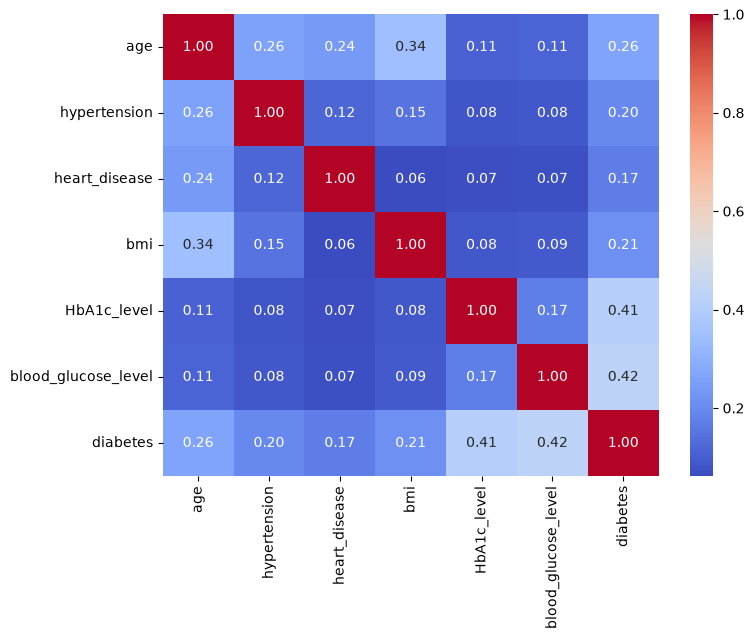

In [58]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.show()

In [59]:
df["bmi_missing"]=(df["bmi"] == 27.32).astype(int)

In [60]:
df.shape

(96128, 10)

In [61]:
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes,bmi_missing
0,Female,80.0,0,1,never,25.19,6.6,140,0,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0,1
2,Male,28.0,0,0,never,27.32,5.7,158,0,1
3,Female,36.0,0,0,current,23.45,5.0,155,0,0
4,Male,76.0,1,1,current,20.14,4.8,155,0,0


In [62]:
from sklearn.model_selection import train_test_split
X = df.drop(columns="diabetes")
y = df["diabetes"]

X_temp ,X_test ,y_temp ,y_test = train_test_split(X,y,test_size=.15,stratify=y,random_state =42)
X_train ,X_val ,y_train ,y_val = train_test_split(X_temp,y_temp,test_size=.15/.85,stratify=y_temp,random_state =42)

In [63]:
for name , y_part in [("train",y_train),("val",y_val),("test",y_test)]:
    print(name ,len(y_part),f"{y_part.mean()*100:.2f}% positive")

train 67288 8.82% positive
val 14420 8.82% positive
test 14420 8.82% positive


In [64]:
import os 
os.makedirs("../data/processed",exist_ok =True)

X_train.assign(diabetes=y_train).to_csv("../data/processed/train.csv",index = False)
X_val.assign(diabetes=y_val).to_csv("../data/processed/val.csv",index = False)
X_test.assign(diabetes=y_test).to_csv("../data/processed/test.csv",index = False)

In [65]:
df.info()

<class 'pandas.DataFrame'>
Index: 96128 entries, 0 to 96145
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   gender               96128 non-null  str    
 1   age                  96128 non-null  float64
 2   hypertension         96128 non-null  int64  
 3   heart_disease        96128 non-null  int64  
 4   smoking_history      96128 non-null  str    
 5   bmi                  96128 non-null  float64
 6   HbA1c_level          96128 non-null  float64
 7   blood_glucose_level  96128 non-null  int64  
 8   diabetes             96128 non-null  int64  
 9   bmi_missing          96128 non-null  int64  
dtypes: float64(3), int64(5), str(2)
memory usage: 8.1 MB


## Baseline Model 


In [66]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.linear_model import LogisticRegression

In [67]:
num_cols = ["age","bmi","blood_glucose_level","HbA1c_level"]
cat_cols = ["gender","smoking_history"]
bin_cols = ["hypertension","heart_disease","bmi_missing"]

In [68]:
preprocessor = ColumnTransformer([
    ("num_cols",StandardScaler(),num_cols),
    ("cat_cols",OneHotEncoder(),cat_cols),
    ("bin", "passthrough",bin_cols)
])

baseline = Pipeline([
    ("preprocessor",preprocessor),
    ("clf",LogisticRegression(class_weight="balanced",max_iter=1000,random_state=42))
])

baseline.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['gender','age','hypertension',...,'HbA1c_level','blood_glucose_level', 'bmi_missing']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_cols', ...), ('cat_cols', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remai

In [69]:
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, average_precision_score, ConfusionMatrixDisplay ,recall_score, precision_score, f1_score)

y_pred = baseline.predict(X_val)
y_proba = baseline.predict_proba(X_val)[:, 1]
cm = confusion_matrix(y_val, y_pred)
print(classification_report(y_val, y_pred, digits=3))
print(cm)
print("ROC-AUC:", roc_auc_score(y_val, y_proba))
print("PR-AUC :", average_precision_score(y_val, y_proba))

              precision    recall  f1-score   support

           0      0.988     0.893     0.938     13148
           1      0.444     0.884     0.591      1272

    accuracy                          0.892     14420
   macro avg      0.716     0.888     0.764     14420
weighted avg      0.940     0.892     0.907     14420

[[11738  1410]
 [  148  1124]]
ROC-AUC: 0.964365948476273
PR-AUC : 0.8238136154289313


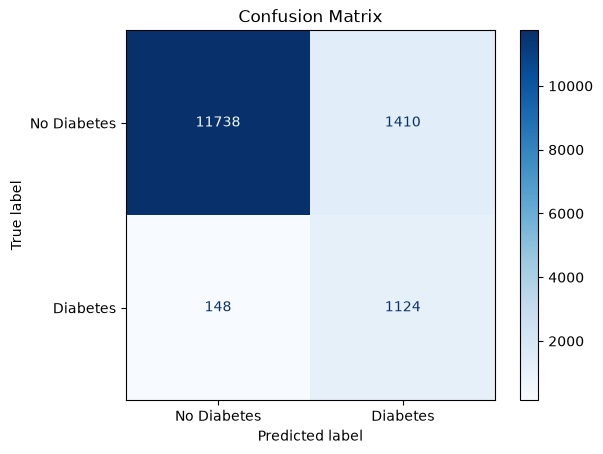

In [70]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=["No Diabetes", "Diabetes"]
)
disp.plot(cmap="Blues")

plt.title("Confusion Matrix")
plt.show()

In [ ]:
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

pos = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    "LogisticRegression" : LogisticRegression(
        class_weight="balanced",max_iter=1000,
        random_state=42),
    "RandomForest": RandomForestClassifier(
        n_estimators=300, class_weight="balanced",
        n_jobs=-1, random_state=42),
    "XGBoost": XGBClassifier(
        n_estimators=300, learning_rate=0.1,
        scale_pos_weight=pos, eval_metric="logloss",
        n_jobs=-1, random_state=42),
    "LightGBM": LGBMClassifier(
        n_estimators=300, learning_rate=0.1,
        scale_pos_weight=pos,
        n_jobs=-1, random_state=42, verbose=-1)
}

results = []
for name , clf in models.items():
    pipe = Pipeline([("prep",preprocessor),("cls",clf)])
    pipe.fit(X_train,y_train)
    y_pred = pipe.predict(X_val)
    y_proba= pipe.predict_proba(X_val)[:,1]
    results.append({
        "model": name,
        "recall": recall_score(y_val, y_pred),
        "precision": precision_score(y_val, y_pred),
        "f1": f1_score(y_val, y_pred),
        "roc_auc": roc_auc_score(y_val, y_proba),
        "pr_auc": average_precision_score(y_val, y_proba)
    })

pd.DataFrame(results).round(3)

,model,recall,precision,f1,roc_auc,pr_auc
0,LogisticRegression,0.884,0.444,0.591,0.964,0.824
1,RandomForest,0.754,0.787,0.770,0.970,0.852
2,XGBoost,0.888,0.528,0.662,0.978,0.882
3,LightGBM,0.873,0.554,0.678,0.978,0.880


In [72]:
from sklearn.metrics import precision_recall_curve

target_recall = 0.90
fitted = {}
rows = []

all_models = {
    "LogReg": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
    **models
}

for name, clf in all_models.items():
    pipe = Pipeline([("prep", preprocessor), ("clf", clf)])
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    proba = pipe.predict_proba(X_val)[:, 1]

    prec, rec, thr = precision_recall_curve(y_val, proba)
    mask = rec[:-1] >= target_recall
    best = prec[:-1][mask].max()
    t = thr[mask][prec[:-1][mask].argmax()]
    rows.append({
        "model": name,
        f"precision@recall>={target_recall}": round(best, 3),
        "threshold": round(t, 3)
    })

pd.DataFrame(rows)

,model,precision@recall>=0.9,threshold
0,LogReg,0.420,0.460
1,LogisticRegression,0.420,0.460
2,RandomForest,0.478,0.193
3,XGBoost,0.508,0.472
4,LightGBM,0.491,0.402


In [73]:
from sklearn.model_selection import StratifiedKFold, cross_validate

X_dev = pd.concat([X_train,X_val])
y_dev = pd.concat([y_train,y_val])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

pos = (y_dev == 0).sum() / (y_dev == 1).sum()

cv_models = {
    "LogReg": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
    "RandomForest": RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.1, scale_pos_weight=pos, eval_metric="logloss", n_jobs=-1, random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=300, learning_rate=0.1, scale_pos_weight=pos, n_jobs=-1, random_state=42, verbose=-1),
}
cv_rows = []

for name , clf in cv_models.items():
    pipe = Pipeline([
        ("prep",preprocessor),
        ("clf",clf)
    ])
    scores = cross_validate(
        pipe, X_dev, y_dev, cv=cv,
        scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"},
        n_jobs=1,
    )
    cv_rows.append({
        "model": name,
        "pr_auc_mean": scores["test_pr_auc"].mean(),
        "pr_auc_std": scores["test_pr_auc"].std(),
        "roc_auc_mean": scores["test_roc_auc"].mean(),
        "roc_auc_std": scores["test_roc_auc"].std(),
    })

pd.DataFrame(cv_rows).round(4)

,model,pr_auc_mean,pr_auc_std,roc_auc_mean,roc_auc_std
0,LogReg,0.8197,0.0065,0.9621,0.0023
1,RandomForest,0.8486,0.0087,0.9685,0.0033
2,XGBoost,0.8788,0.0067,0.9763,0.0016
3,LightGBM,0.8752,0.0075,0.9753,0.0016


In [74]:
import optuna 
from sklearn.model_selection import cross_val_score

optuna.logging.set_verbosity(optuna.logging.WARNING)

cv3 = StratifiedKFold(n_splits=3,shuffle=True,random_state=42)

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 600),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "max_depth": trial.suggest_int("max_depth", 3, 8),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
        "scale_pos_weight": trial.suggest_float("scale_pos_weight", 1, pos),
    }
    clf = XGBClassifier(**params, eval_metric="logloss", n_jobs=-1, random_state=42)
    pipe = Pipeline([("prep", preprocessor), ("clf", clf)])
    return cross_val_score(pipe, X_dev, y_dev, cv=cv3, scoring="average_precision").mean()

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=30, show_progress_bar=True)

print("Best PR-AUC:", study.best_value)
print(study.best_params)

  0%|          | 0/30 [00:00<?, ?it/s]

Best PR-AUC: 0.8899172059604661
{'n_estimators': 170, 'learning_rate': 0.11784576811599486, 'max_depth': 3, 'min_child_weight': 8, 'subsample': 0.8560652947304449, 'colsample_bytree': 0.6595461607901565, 'reg_lambda': 2.451501525033984, 'scale_pos_weight': 8.245308107972834}


In [75]:
best_params = study.best_params

best_pipe = Pipeline([
    ("prep", preprocessor),
    ("clf", XGBClassifier(**best_params, eval_metric="logloss", n_jobs=-1, random_state=42)),
])

scores = cross_validate(
    best_pipe, X_dev, y_dev, cv=cv, 
    scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"},
)

print(f"PR-AUC : {scores['test_pr_auc'].mean():.4f} ± {scores['test_pr_auc'].std():.4f}")
print(f"ROC-AUC: {scores['test_roc_auc'].mean():.4f} ± {scores['test_roc_auc'].std():.4f}")

PR-AUC : 0.8901 ± 0.0086
ROC-AUC: 0.9796 ± 0.0020


In [76]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

oof_proba = cross_val_predict(
    best_pipe, X_dev, y_dev, cv=cv, method="predict_proba"
)[:, 1]

prec, rec, thr = precision_recall_curve(y_dev, oof_proba)

target_recall = 0.90
mask = rec[:-1] >= target_recall
best_idx = prec[:-1][mask].argmax()
threshold = thr[mask][best_idx]

print("Threshold:", round(threshold, 3))
print("Precision @ recall>=0.90:", round(prec[:-1][mask][best_idx], 3))

Threshold: 0.505
Precision @ recall>=0.90: 0.531


In [77]:
best_pipe.fit(X_dev, y_dev)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['gender','age','hypertension',...,'HbA1c_level','blood_glucose_level', 'bmi_missing']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_cols', ...), ('cat_cols', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pa

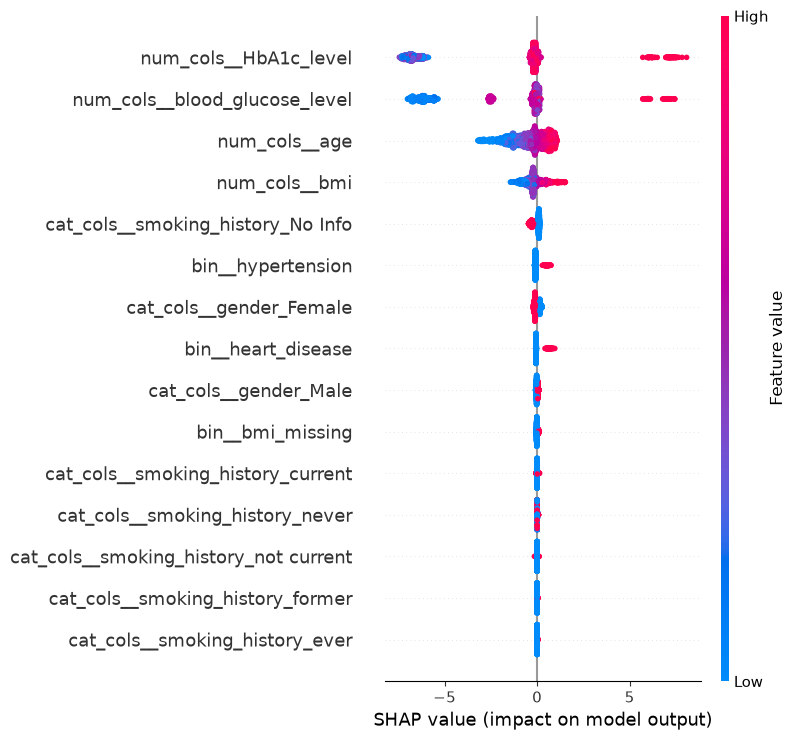

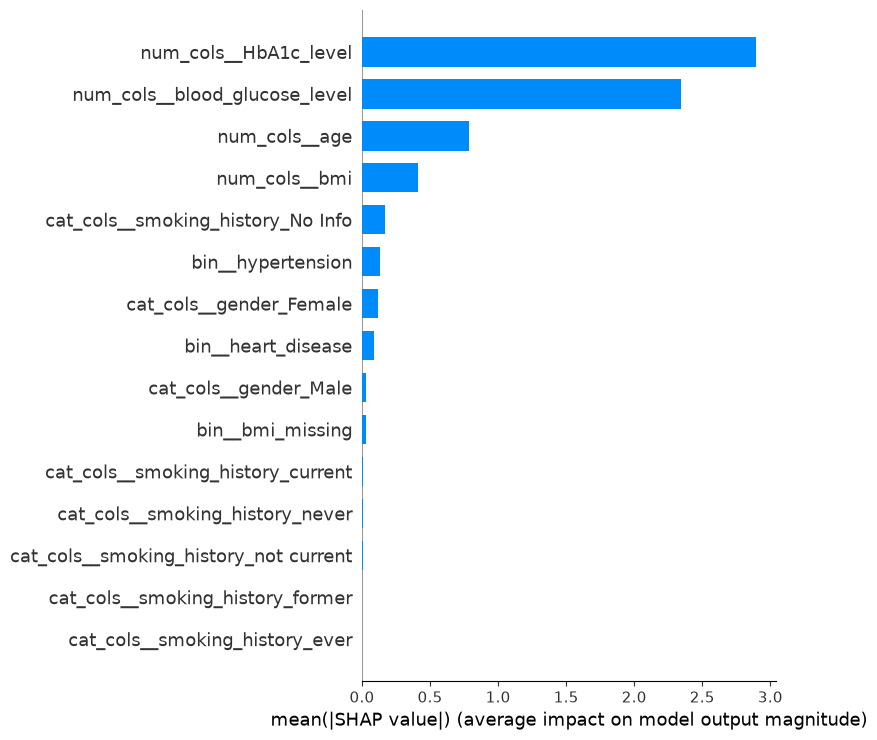

In [78]:
import shap

prep = best_pipe.named_steps["prep"]
clf = best_pipe.named_steps["clf"]

X_sample = X_val.sample(2000, random_state=42)
X_sample_t = prep.transform(X_sample)
feature_names = prep.get_feature_names_out()

explainer = shap.TreeExplainer(clf)
shap_values = explainer.shap_values(X_sample_t)

shap.summary_plot(shap_values, X_sample_t, feature_names=feature_names)
shap.summary_plot(shap_values, X_sample_t, feature_names=feature_names, plot_type="bar")

In [ ]:
num_cols_reduced = ["age", "bmi"]
drop_cols = ["HbA1c_level", "blood_glucose_level"]

preprocessor_reduced = ColumnTransformer([
    ("num", StandardScaler(), num_cols_reduced),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("bin", "passthrough", bin_cols),
])

reduced_pipe = Pipeline([
    ("prep", preprocessor_reduced),
    ("clf", XGBClassifier(**best_params, eval_metric="logloss", n_jobs=-1, random_state=42)),
])

X_dev_reduced = X_dev.drop(columns=drop_cols)
print(X_dev_reduced.columns.tolist())  

scores_reduced = cross_validate(
    reduced_pipe, X_dev_reduced, y_dev, cv=cv,
    scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"},
)

print(f"PR-AUC : {scores_reduced['test_pr_auc'].mean():.4f} ± {scores_reduced['test_pr_auc'].std():.4f}")
print(f"ROC-AUC: {scores_reduced['test_roc_auc'].mean():.4f} ± {scores_reduced['test_roc_auc'].std():.4f}")

['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'bmi_missing']
PR-AUC : 0.3279 ± 0.0062
ROC-AUC: 0.8342 ± 0.0030


In [ ]:
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
)

# تأكد إن best_pipe متدرب على X_dev بالـ preprocessor الصح
best_pipe.fit(X_dev, y_dev)

threshold = 0.505
test_proba = best_pipe.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= threshold).astype(int)

print(classification_report(y_test, test_pred, digits=3))
print(confusion_matrix(y_test, test_pred))
print("ROC-AUC:", roc_auc_score(y_test, test_proba))
print("PR-AUC :", average_precision_score(y_test, test_proba))

              precision    recall  f1-score   support

           0      0.988     0.919     0.953     13148
           1      0.515     0.889     0.653      1272

    accuracy                          0.917     14420
   macro avg      0.752     0.904     0.803     14420
weighted avg      0.947     0.917     0.926     14420

[[12085  1063]
 [  141  1131]]
ROC-AUC: 0.9781512552785607
PR-AUC : 0.8836423756324775


In [82]:
print(best_params)

{'n_estimators': 170, 'learning_rate': 0.11784576811599486, 'max_depth': 3, 'min_child_weight': 8, 'subsample': 0.8560652947304449, 'colsample_bytree': 0.6595461607901565, 'reg_lambda': 2.451501525033984, 'scale_pos_weight': 8.245308107972834}
